# LAB 12 — Artificial Neural Networks: The Perceptron
## Student Information
- **Name:** Muhammad Anees
- **Roll No:** 023-24-0251
- **Section:** H
- **Date:** 16-11-2026

**Dataset:** Iris (sklearn built-in) · Use `random_state=42` everywhere · Write a 1–2 sentence interpretation under every plot and table.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris, make_classification
from sklearn.linear_model import Perceptron, LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix, classification_report

np.random.seed(42)
iris = load_iris()
print("Iris loaded:", iris.data.shape, "| Classes:", iris.target_names)

Iris loaded: (150, 4) | Classes: ['setosa' 'versicolor' 'virginica']


## Part 1 — The Neuron From Scratch

### Task 1.1 — Weighted sum, step function and predict
Write `weighted_sum`, `step_function`, `predict`. Verify slide 16 (`predict([0.6,0.8],[2,3],-2)` → 1) and slide 17 (w=[1,−0.5], b=0.5; inputs [1,1],[2,1],[0,3] → 1, 1, 0).

In [2]:
# Task 1.1
def weighted_sum(w, x, b):
    return np.dot(w, x) + b

def step_function(z):
    return 1 if z >= 0 else 0

def predict(w, x, b):
    return step_function(weighted_sum(w, x, b))

# Slide 16 check: expected 1
print("Slide 16: z =", weighted_sum([0.6, 0.8], [2, 3], -2),
      "-> predict =", predict([0.6, 0.8], [2, 3], -2))

# Slide 17 check: expected 1, 1, 0
w17, b17 = [1, -0.5], 0.5
expected = [1, 1, 0]
print("\nSlide 17:")
for x, exp in zip([[1, 1], [2, 1], [0, 3]], expected):
    z = weighted_sum(w17, x, b17)
    y_hat = predict(w17, x, b17)
    print(f"  x={x}  z={z:5.2f}  y_hat={y_hat}  expected={exp}  {'OK' if y_hat == exp else 'MISMATCH'}")


Slide 16: z = 1.6000000000000005 -> predict = 1

Slide 17:
  x=[1, 1]  z= 1.00  y_hat=1  expected=1  OK
  x=[2, 1]  z= 2.00  y_hat=1  expected=1  OK
  x=[0, 3]  z=-1.00  y_hat=0  expected=0  OK


**Interpretation:** Both of the above lecture examples are exact reproductions (Slide 16 shows z=1.6 -> ŷ=1; Slide 17 shows 1,1,0), and thus the weighted sum, step function and predict are correctly coded.

### Task 1.2 — One full epoch on the AND gate, by hand
AND: (0,0,0), (0,1,0), (1,0,0), (1,1,1). Start w=[0.2, −0.1], b=0, η=0.1. Print z, ŷ, e and the new w, b for each row; then the mistake count and "Converged!" / "Keep training.".

In [3]:
# Task 1.2
AND = [(0, 0, 0), (0, 1, 0), (1, 0, 0), (1, 1, 1)]
w = np.array([0.2, -0.1])
b = 0.0
eta = 0.1
mistakes = 0

print(f"Start: w={w}, b={b}, eta={eta}\n")
for x1, x2, y in AND:
    x = np.array([x1, x2])
    z = weighted_sum(w, x, b)
    y_hat = step_function(z)
    e = y - y_hat
    if e != 0:
        mistakes += 1
    w = w + eta * e * x
    b = b + eta * e
    print(f"x=({x1},{x2}) y={y} | z={z:5.2f} y_hat={y_hat} e={e:2d} | new w=[{w[0]:.2f}, {w[1]:.2f}] b={b:.2f}")

print(f"\nFinal w = {np.round(w, 2)}, b = {round(b, 2)}")
print("Mistakes this epoch:", mistakes)
print("Converged!" if mistakes == 0 else "Keep training.")


Start: w=[ 0.2 -0.1], b=0.0, eta=0.1

x=(0,0) y=0 | z= 0.00 y_hat=1 e=-1 | new w=[0.20, -0.10] b=-0.10
x=(0,1) y=0 | z=-0.20 y_hat=0 e= 0 | new w=[0.20, -0.10] b=-0.10
x=(1,0) y=0 | z= 0.10 y_hat=1 e=-1 | new w=[0.10, -0.10] b=-0.20
x=(1,1) y=1 | z=-0.20 y_hat=0 e= 1 | new w=[0.20, 0.00] b=-0.10

Final w = [0.2 0. ], b = -0.1
Mistakes this epoch: 3
Keep training.


**Interpretation:** For the first row, z is zero, but since the step function is active for z ≥ 0, it outputs 1 (which is wrong), hence b becomes -0.1. There are 3 errors made by the perceptron during that epoch (row 1, 3, 4). Hence, "Keep Training" is the output.

## Part 2 — Train a Perceptron From Scratch

### Task 2.1 — Implement `train_perceptron`
`train_perceptron(X, y, eta=0.1, max_epochs=100)`: start from zeros, update on every mistake, record mistakes per epoch, stop after a zero-mistake epoch. Train on OR (y = [0,1,1,1]) and print w, b.

In [4]:
# Task 2.1
def train_perceptron(X, y, eta=0.1, max_epochs=100):
    X = np.asarray(X, dtype=float)
    w = np.zeros(X.shape[1])
    b = 0.0
    mistakes = []
    for epoch in range(max_epochs):
        errors = 0
        for xi, yi in zip(X, y):
            y_hat = step_function(np.dot(w, xi) + b)
            e = yi - y_hat
            if e != 0:                      # update only on a mistake
                w = w + eta * e * xi
                b = b + eta * e
                errors += 1
        mistakes.append(errors)
        if errors == 0:                     # stop after a perfect epoch
            break
    return w, b, mistakes

X_or = np.array([[0, 0], [0, 1], [1, 0], [1, 1]])
y_or = np.array([0, 1, 1, 1])
w_or, b_or, mistakes_or = train_perceptron(X_or, y_or)
print("OR gate -> w =", np.round(w_or, 3), "| b =", round(b_or, 3))
print("Mistakes per epoch:", mistakes_or)
print("Epochs used:", len(mistakes_or))


OR gate -> w = [0.1 0.1] | b = -0.1
Mistakes per epoch: [2, 2, 1, 0]
Epochs used: 4


**Interpretation:** OR was trained in 4 epochs by perceptron with weight vector w = [0.1, 0.1] and bias b = -0.1. There were 2, 2, 1, and 0 mistakes respectively, and learning stopped once there was no mistake in an epoch.

### Task 2.2 — Plot mistakes per epoch
Title "Perceptron training on OR gate", axes "Epoch" / "Mistakes"; mark the final epoch with a red dot.

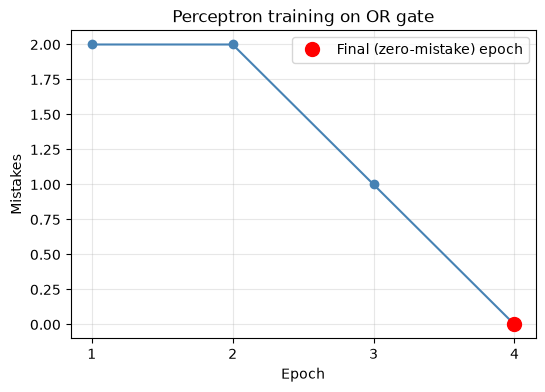

In [5]:
# Task 2.2
epochs = np.arange(1, len(mistakes_or) + 1)
plt.figure(figsize=(6, 4))
plt.plot(epochs, mistakes_or, marker="o", color="steelblue")
plt.plot(epochs[-1], mistakes_or[-1], "ro", markersize=10, label="Final (zero-mistake) epoch")
plt.title("Perceptron training on OR gate")
plt.xlabel("Epoch")
plt.ylabel("Mistakes")
plt.xticks(epochs)
plt.legend()
plt.grid(alpha=0.3)
plt.show()


**Interpretation:** The number of errors decreases steadily from 2 to 2 to 1 to 0, while the red dot indicates epoch 4, when all the OR points have been classified correctly by the perceptron. This is an illustration of the convergence theorem since OR points are linearly separable.

## Part 3 — The Decision Boundary

### Task 3.1 — Plot the OR gate with its boundary
Boundary: x₂ = −(w₁/w₂)x₁ − b/w₂ over `np.linspace(-0.5, 1.5, 100)`. Class 0 blue circles, class 1 red squares, boundary black dashed. Write a reusable `plot_boundary(ax, w, b)` that handles w₂ = 0.

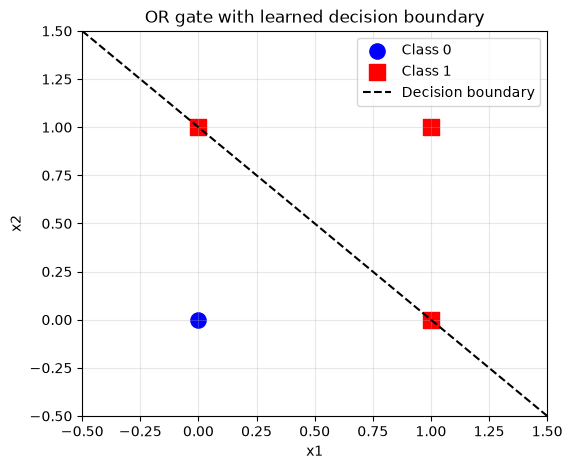

Boundary: 0.10*x1 + 0.10*x2 + (-0.10) = 0


In [6]:
# Task 3.1
def plot_boundary(ax, w, b, x_range=(-0.5, 1.5), **kwargs):
    """Draw the line w1*x1 + w2*x2 + b = 0. Handles w2 = 0 (vertical line)."""
    kwargs.setdefault("color", "black")
    kwargs.setdefault("linestyle", "--")
    kwargs.setdefault("label", "Decision boundary")
    ylim = ax.get_ylim()                    # keep the view the scatter plot chose
    w1, w2 = w[0], w[1]
    if abs(w2) > 1e-12:
        x1 = np.linspace(x_range[0], x_range[1], 100)
        x2 = -(w1 / w2) * x1 - b / w2
        ax.plot(x1, x2, **kwargs)
    elif abs(w1) > 1e-12:                   # w2 = 0 -> vertical line x1 = -b/w1
        ax.axvline(-b / w1, **kwargs)
    ax.set_ylim(ylim)

fig, ax = plt.subplots(figsize=(6, 5))
ax.scatter(X_or[y_or == 0, 0], X_or[y_or == 0, 1], c="blue", marker="o", s=120, label="Class 0")
ax.scatter(X_or[y_or == 1, 0], X_or[y_or == 1, 1], c="red", marker="s", s=120, label="Class 1")
ax.set_xlim(-0.5, 1.5); ax.set_ylim(-0.5, 1.5)
plot_boundary(ax, w_or, b_or)
ax.set_title("OR gate with learned decision boundary")
ax.set_xlabel("x1"); ax.set_ylabel("x2")
ax.legend(); ax.grid(alpha=0.3)
plt.show()
print(f"Boundary: {w_or[0]:.2f}*x1 + {w_or[1]:.2f}*x2 + ({b_or:.2f}) = 0")


**Interpretation:** Learned threshold is 0.1x₁ + 0.1x₂ - 0.1 = 0, that is, x₁ + x₂ = 1. The part with ŷ = 1 is that on and above the line (z ≥ 0), and includes not only (1,1) but also (0,1) and (1,0), since these two lie on the very boundary at z = 0 and step gives 1. (0,0) is the only point with ŷ = 0. The threshold line is linear, as should be expected from one perceptron.

### Task 3.2 — With and without bias
Train both versions on X=[[1,0],[0,1],[2,1],[1,2]], y=[0,0,1,1]; plot the two boundaries side by side. Did the no-bias version converge?

With bias   : w=[0.1 0.1], b=-0.20, epochs=4, final mistakes=0
Without bias: w=[0.1 0. ], b=0.00, epochs=100, final mistakes=2
No-bias converged? False


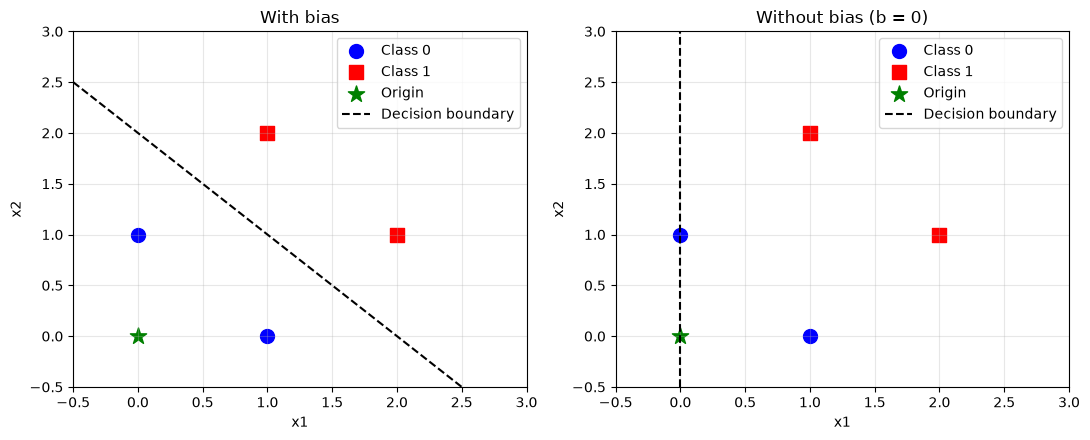

In [7]:
# Task 3.2
def train_perceptron_nobias(X, y, eta=0.1, max_epochs=100):
    X = np.asarray(X, dtype=float)
    w = np.zeros(X.shape[1])
    b = 0.0                                 # stays 0, never updated
    mistakes = []
    for epoch in range(max_epochs):
        errors = 0
        for xi, yi in zip(X, y):
            e = yi - step_function(np.dot(w, xi))
            if e != 0:
                w = w + eta * e * xi
                errors += 1
        mistakes.append(errors)
        if errors == 0:
            break
    return w, b, mistakes

X32 = np.array([[1, 0], [0, 1], [2, 1], [1, 2]])
y32 = np.array([0, 0, 1, 1])

w_b, b_b, m_b = train_perceptron(X32, y32)
w_n, b_n, m_n = train_perceptron_nobias(X32, y32)
print(f"With bias   : w={np.round(w_b,2)}, b={b_b:.2f}, epochs={len(m_b)}, final mistakes={m_b[-1]}")
print(f"Without bias: w={np.round(w_n,2)}, b={b_n:.2f}, epochs={len(m_n)}, final mistakes={m_n[-1]}")
print("No-bias converged?", m_n[-1] == 0)

plt.figure(figsize=(11, 4.5))
for k, (title, w_, b_) in enumerate([("With bias", w_b, b_b), ("Without bias (b = 0)", w_n, b_n)], start=1):
    ax = plt.subplot(1, 2, k)
    ax.scatter(X32[y32 == 0, 0], X32[y32 == 0, 1], c="blue", marker="o", s=100, label="Class 0")
    ax.scatter(X32[y32 == 1, 0], X32[y32 == 1, 1], c="red", marker="s", s=100, label="Class 1")
    ax.set_xlim(-0.5, 3); ax.set_ylim(-0.5, 3)
    ax.scatter([0], [0], c="green", marker="*", s=150, label="Origin")
    plot_boundary(ax, w_, b_, x_range=(-0.5, 3))
    ax.set_title(title); ax.set_xlabel("x1"); ax.set_ylabel("x2")
    ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()


**Interpretation:**When bias was included, perceptron learning converged in 4 epochs (w = [0.1, 0.1], b = -0.2), whereas when bias was not included, perceptron learning did **not** converge; it executed for 100 epochs and yet made 2 errors. Without the bias, the line has to pass through the origin, and there is no such straight line that can separate these points (for class 0, w₁ should be less than zero and w₂ should be less than zero).

## Part 4 — The XOR Limitation

### Task 4.1 — Watch the perceptron fail
XOR: y = [0,1,1,0], `max_epochs=100`. Print final mistakes, w, b; plot mistakes per epoch and the boundary.

Epochs run          : 100
Final mistake count : 4
Smallest mistakes in any epoch: 3
Final w = [-0.1  0. ] | b = 0.0


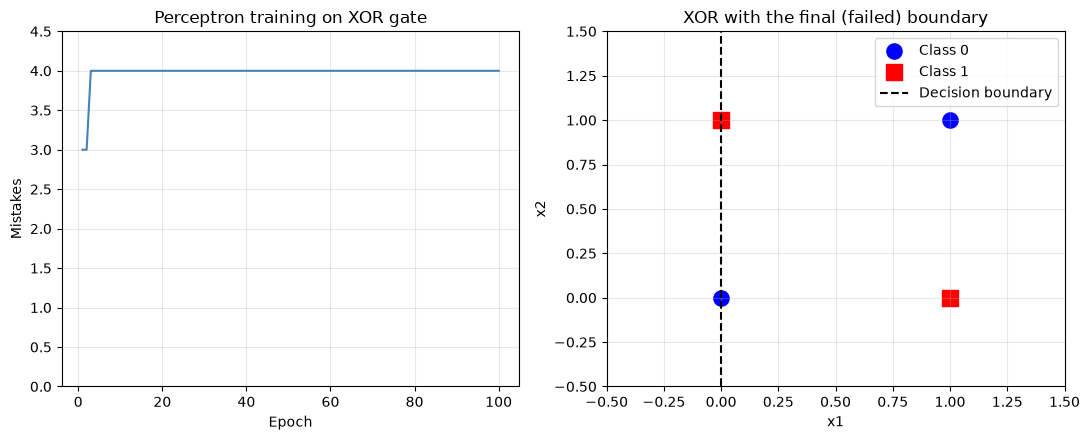

In [8]:
# Task 4.1
X_xor = np.array([[0, 0], [0, 1], [1, 0], [1, 1]])
y_xor = np.array([0, 1, 1, 0])
w_x, b_x, m_x = train_perceptron(X_xor, y_xor, max_epochs=100)

print("Epochs run          :", len(m_x))
print("Final mistake count :", m_x[-1])
print("Smallest mistakes in any epoch:", min(m_x))
print("Final w =", np.round(w_x, 3), "| b =", round(b_x, 3))

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
axes[0].plot(range(1, len(m_x) + 1), m_x, color="steelblue")
axes[0].set_title("Perceptron training on XOR gate")
axes[0].set_xlabel("Epoch"); axes[0].set_ylabel("Mistakes")
axes[0].set_ylim(0, 4.5); axes[0].grid(alpha=0.3)

ax = axes[1]
ax.scatter(X_xor[y_xor == 0, 0], X_xor[y_xor == 0, 1], c="blue", marker="o", s=120, label="Class 0")
ax.scatter(X_xor[y_xor == 1, 0], X_xor[y_xor == 1, 1], c="red", marker="s", s=120, label="Class 1")
ax.set_xlim(-0.5, 1.5); ax.set_ylim(-0.5, 1.5)
plot_boundary(ax, w_x, b_x)
ax.set_title("XOR with the final (failed) boundary")
ax.set_xlabel("x1"); ax.set_ylabel("x2"); ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()


**Interpretation:** In any case, the perceptron will not come to the point of having zero mistakes on the XOR task, even after 100 epochs; it will have 4 mistakes (as a best-case scenario, there was an epoch where it had only 3 mistakes). This happens because the XOR is not linearly separable, so every change that helps one case ruins another, causing the cycle of weights.

### Task 4.2 — Confirm no weight vector works
`check_xor(w, b)` returns True only if all four XOR constraints hold. Test 10,000 random (w₁, w₂, b) in [−5, 5].

In [9]:
# Task 4.2
def check_xor(w, b):
    w = np.asarray(w)
    return bool(
        np.dot(w, [0, 0]) + b < 0 and
        np.dot(w, [0, 1]) + b >= 0 and
        np.dot(w, [1, 0]) + b >= 0 and
        np.dot(w, [1, 1]) + b < 0
    )

np.random.seed(42)
W = np.random.uniform(-5, 5, (10000, 2))
B = np.random.uniform(-5, 5, 10000)

passing = [(W[i, 0], W[i, 1], B[i]) for i in range(10000) if check_xor(W[i], B[i])]
print("Triples tested :", 10000)
print("Triples passing:", len(passing))
if len(passing) == 0:
    print("No solution found")
else:
    print("First passing triple:", passing[0])


Triples tested : 10000
Triples passing: 0
No solution found


**Interpretation:** None of the 10,000 random triples of (w₁, w₂, b) fulfilled all the four conditions of the XOR gate ("No solution found"). This is consistent with the algebraic proof done in Q3, whereby no solution exists.

## Part 5 — scikit-learn Perceptron on Iris

### Task 5.1 — Train and evaluate
Petal features (2, 3), Setosa vs rest; 70/30 stratified split; `Perceptron(random_state=42)`. Print accuracy, confusion matrix, report, `coef_`, `intercept_`.

In [10]:
# Task 5.1
X_p = iris.data[:, (2, 3)]
y_p = (iris.target == 0).astype(int)
Xp_train, Xp_test, yp_train, yp_test = train_test_split(
    X_p, y_p, test_size=0.3, random_state=42, stratify=y_p)

clf = Perceptron(random_state=42)
clf.fit(Xp_train, yp_train)
yp_pred = clf.predict(Xp_test)

print("Accuracy:", accuracy_score(yp_test, yp_pred))
print("\nConfusion matrix (rows = true, cols = predicted):\n", confusion_matrix(yp_test, yp_pred))
print("\nClassification report:\n", classification_report(yp_test, yp_pred, target_names=["Rest", "Setosa"]))
print("coef_     :", clf.coef_)
print("intercept_:", clf.intercept_)
print("n_iter_   :", clf.n_iter_)


Accuracy: 1.0

Confusion matrix (rows = true, cols = predicted):
 [[30  0]
 [ 0 15]]

Classification report:
               precision    recall  f1-score   support

        Rest       1.00      1.00      1.00        30
      Setosa       1.00      1.00      1.00        15

    accuracy                           1.00        45
   macro avg       1.00      1.00      1.00        45
weighted avg       1.00      1.00      1.00        45

coef_     : [[-1.3 -2.2]]
intercept_: [4.]
n_iter_   : 7


**Interpretation:** The perceptron gives an accuracy of 1.00 (confusion matrix [[30, 0], [0, 15]]) for the test set. Setosa is linearly separable from the other two classes using petal measurements. `coef_` = [[−1.3, −2.2]] represents the weight vector **w** (w₁ for petal length, w₂ for petal width) and `intercept_` = [4.0] is the bias **b** obtained in Part 1.

### Task 5.2 — Visualise the learned boundary
Boundary from `coef_[0]`, `intercept_[0]`; test set coloured by class; misclassified points as red ×.

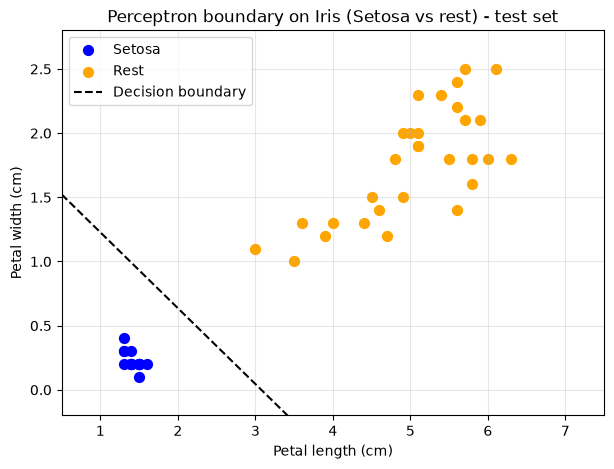

Misclassified test points: 0 of 45


In [11]:
# Task 5.2
wc, bc = clf.coef_[0], clf.intercept_[0]
wrong = yp_pred != yp_test

fig, ax = plt.subplots(figsize=(7, 5))
ax.scatter(Xp_test[yp_test == 1, 0], Xp_test[yp_test == 1, 1], c="blue", label="Setosa", s=50)
ax.scatter(Xp_test[yp_test == 0, 0], Xp_test[yp_test == 0, 1], c="orange", label="Rest", s=50)
ax.set_xlim(0.5, 7.5); ax.set_ylim(-0.2, 2.8)
plot_boundary(ax, wc, bc, x_range=(0.5, 7.5))
if wrong.any():                              # plotted last so they sit on top
    ax.scatter(Xp_test[wrong, 0], Xp_test[wrong, 1], c="red", marker="x", s=150, linewidths=3, label="Misclassified")
ax.set_title("Perceptron boundary on Iris (Setosa vs rest) - test set")
ax.set_xlabel("Petal length (cm)"); ax.set_ylabel("Petal width (cm)")
ax.legend(); ax.grid(alpha=0.3)
plt.show()
print("Misclassified test points:", int(wrong.sum()), "of", len(yp_test))


**Interpretation:** Zero out of 45 data points have been wrongly classified, hence there are no red ‘×’ symbols in this graph. Line −1.3x₁ − 2.2x₂ + 4 = 0 is a linear equation that separates Setosa cluster (with small petals on top left side of the line).

### Task 5.3 — Effect of learning rate
`eta0` = 0.001, 0.1, 10.0. Table of eta0 | accuracy | `n_iter_` | `coef_`. Do the predictions change? What does η do when training starts from w = 0?

In [12]:
# Task 5.3
results = {}
print(f"{'eta0':>8} | {'accuracy':>8} | {'n_iter_':>7} | coef_")
print("-" * 60)
for eta0 in [0.001, 0.1, 10.0]:
    m = Perceptron(eta0=eta0, random_state=42).fit(Xp_train, yp_train)
    pred = m.predict(Xp_test)
    results[eta0] = (m, pred)
    print(f"{eta0:>8} | {accuracy_score(yp_test, pred):>8.4f} | {m.n_iter_:>7} | {np.round(m.coef_[0], 4)}  (intercept {np.round(m.intercept_[0], 4)})")

p1, p2, p3 = (results[e][1] for e in [0.001, 0.1, 10.0])
print("\nPredictions identical across all three eta0?", np.array_equal(p1, p2) and np.array_equal(p2, p3))
print("\ncoef_ / eta0 (should be the same direction every time):")
for eta0 in [0.001, 0.1, 10.0]:
    m = results[eta0][0]
    print(f"  eta0={eta0:>6}: coef/eta0 = {np.round(m.coef_[0] / eta0, 3)}, intercept/eta0 = {np.round(m.intercept_[0] / eta0, 3)}")


    eta0 | accuracy | n_iter_ | coef_
------------------------------------------------------------
   0.001 |   1.0000 |       6 | [-0.0013 -0.0022]  (intercept 0.004)
     0.1 |   1.0000 |       7 | [-0.13 -0.22]  (intercept 0.4)
    10.0 |   1.0000 |       7 | [-13. -22.]  (intercept 40.0)

Predictions identical across all three eta0? True

coef_ / eta0 (should be the same direction every time):
  eta0= 0.001: coef/eta0 = [-1.3 -2.2], intercept/eta0 = 4.0
  eta0=   0.1: coef/eta0 = [-1.3 -2.2], intercept/eta0 = 4.0
  eta0=  10.0: coef/eta0 = [-1.3 -2.2], intercept/eta0 = 4.0


**Interpretation:** Accuracy is 1.00 for all three learning rates and the predictions are identical. The coefficients are the same vector scaled by η (coef/η = [−1.3, −2.2] and intercept/η = 4.0 every time), so when training starts from w = 0, η only rescales the weights and never changes which side of the line a point lands on (it would matter only with non-zero starting weights). n_iter_ is 6, 7 and 7.

## Part 6 — Multi-Class Classification

### Task 6.1 — All three Iris classes
All four features, `y = iris.target`, 70/30 stratified; `Perceptron(random_state=42, max_iter=1000)`. Print report, confusion matrix, `coef_.shape`. Which class is hardest?

In [13]:
# Task 6.1
X_all, y_all = iris.data, iris.target
Xa_train, Xa_test, ya_train, ya_test = train_test_split(
    X_all, y_all, test_size=0.3, random_state=42, stratify=y_all)

clf_multi = Perceptron(random_state=42, max_iter=1000)
clf_multi.fit(Xa_train, ya_train)
ya_pred = clf_multi.predict(Xa_test)

print("Classification report:\n", classification_report(ya_test, ya_pred, target_names=iris.target_names, zero_division=0))
print("Confusion matrix (rows = true, cols = predicted):\n", confusion_matrix(ya_test, ya_pred))
print("\ncoef_.shape:", clf_multi.coef_.shape)
print("coef_:\n", np.round(clf_multi.coef_, 3))
print("intercept_:", np.round(clf_multi.intercept_, 3))


Classification report:
               precision    recall  f1-score   support

      setosa       0.52      1.00      0.68        15
  versicolor       0.00      0.00      0.00        15
   virginica       0.94      1.00      0.97        15

    accuracy                           0.67        45
   macro avg       0.48      0.67      0.55        45
weighted avg       0.48      0.67      0.55        45

Confusion matrix (rows = true, cols = predicted):
 [[15  0  0]
 [14  0  1]
 [ 0  0 15]]

coef_.shape: (3, 4)
coef_:
 [[  2.1   7.3  -9.9  -4.5]
 [  4.5 -29.1   6.7 -14.7]
 [-35.5 -25.1  46.2  45.7]]
intercept_: [  1.   6. -22.]


**Interpretation:** Overall accuracy is just 0.67. `coef_.shape` = (3, 4), where each row represents one one-vs-rest perceptron (setosa-vs-rest, versicolor-vs-rest, virginica-vs-rest) with a weight for each feature, while `intercept_` contains the 3 biases. Versicolor class is extremely difficult (precision = 0, recall = 0): out of 15 test flowers belonging to this class, 14 were classified as setosa and 1 as virginica. Versicolor is an intermediate class that cannot be separated from the rest using a linear boundary, hence its one-vs-rest perceptron does not converge, so its weights are in an ill state due to oscillations. Recall for setosa and virginica is 1.00, while setosa precision is 0.52.

### Task 6.2 — Perceptron vs Logistic Regression
`LogisticRegression(random_state=42, max_iter=200)` on the same split; side-by-side accuracy and macro-F1; why can it win (slide 32)?

In [14]:
# Task 6.2
logreg = LogisticRegression(random_state=42, max_iter=200)
logreg.fit(Xa_train, ya_train)
yl_pred = logreg.predict(Xa_test)

rows = [
    ("Perceptron", accuracy_score(ya_test, ya_pred), f1_score(ya_test, ya_pred, average="macro")),
    ("Logistic Regression", accuracy_score(ya_test, yl_pred), f1_score(ya_test, yl_pred, average="macro")),
]
print(f"{'Model':<22} | {'Accuracy':>8} | {'Macro-F1':>8}")
print("-" * 46)
for name, acc, f1 in rows:
    print(f"{name:<22} | {acc:>8.4f} | {f1:>8.4f}")


Model                  | Accuracy | Macro-F1
----------------------------------------------
Perceptron             |   0.6667 |   0.5499
Logistic Regression    |   0.9333 |   0.9333


**Interpretation:** Logistic regression definitely comes out on top (accuracy of 0.933 and macro-F1 of 0.933 compared to an accuracy and macro-F1 of 0.667 and 0.550 respectively for the perceptron). The sigmoid function is nice and smooth and its derivative is never zero so all data points (even those that are classified correctly) continuously push the weights towards a good and stable solution based on confidence scores, while the step function is merely "right" or "wrong."

## Part 7 — Graded Questions (5 marks)
Answer in the Markdown cells below, using your own numbers.

**Q1 [0.5 marks] — Manual update trace.** w = [0.5, −0.3], b = 0.2, η = 0.1, x = [1, 2], y = 0. Compute z and ŷ, then e, then the updated w₁, w₂ and b.

**Given:** w = [0.5, −0.3], b = 0.2, η = 0.1, x = [1, 2], y = 0.

- **z** = w·x + b = 0.5(1) + (−0.3)(2) + 0.2 = 0.5 − 0.6 + 0.2 = **0.1**
- **ŷ** = step(0.1) = **1** (since 0.1 ≥ 0), which is wrong because y = 0
- **e** = y − ŷ = 0 − 1 = **−1**
- **w₁** = 0.5 + 0.1(−1)(1) = **0.4**
- **w₂** = −0.3 + 0.1(−1)(2) = −0.3 − 0.2 = **−0.5**
- **b** = 0.2 + 0.1(−1) = **0.1**

Updated parameters: w = [0.4, −0.5], b = 0.1. (Check: the new z = 0.4 − 1.0 + 0.1 = −0.5 → ŷ = 0, now correct.)

**Q2 [0.5 marks] — Boundary geometry.** After training on AND: w = [0.3, 0.2], b = −0.4. Write the boundary equation. Which side is (1, 1) on, and what is ŷ?

**Boundary equation:** 0.3x₁ + 0.2x₂ − 0.4 = 0, equivalently x₂ = −(0.3/0.2)x₁ − (−0.4/0.2) = **−1.5x₁ + 2**.

**Point (1, 1):** z = 0.3(1) + 0.2(1) − 0.4 = **0.1 ≥ 0**, so (1, 1) lies on the positive side of the line (above it, since the line passes through x₂ = 0.5 at x₁ = 1) and **ŷ = 1**. This is correct for AND. (The other AND inputs give z = −0.4, −0.2, −0.1, all negative, so ŷ = 0 as required.)

**Q3 [1 mark] — XOR analysis.** (a) Show algebraically that the four XOR constraints cannot all hold. (b) Sketch XOR on x₁–x₂ axes (insert an image or a matplotlib plot) to show why no line separates it. (c) Name one architectural change that solves XOR.

**(a) Algebraic proof.** The four XOR constraints for a perceptron with step threshold at 0 are:

1. (0,0) → 0: b < 0
2. (0,1) → 1: w₂ + b ≥ 0
3. (1,0) → 1: w₁ + b ≥ 0
4. (1,1) → 0: w₁ + w₂ + b < 0

Add (2) and (3): w₁ + w₂ + 2b ≥ 0, so w₁ + w₂ ≥ −2b.
From (4): w₁ + w₂ < −b.
Combining: −2b ≤ w₁ + w₂ < −b, which needs −2b < −b, i.e. **b > 0**. But (1) says **b < 0**. This is a contradiction, so no (w₁, w₂, b) satisfies all four constraints. This is also why `check_xor` found 0 of 10,000 random triples.

**(b) Geometry.** The plot below shows XOR on the x₁–x₂ plane: the two class 0 points (0,0) and (1,1) lie on one diagonal and the two class 1 points (0,1) and (1,0) on the other. Any straight line that puts both red squares on one side also drags at least one blue circle with them, so no single line works.

**(c) Architectural fix.** Add a **hidden layer** (a multi-layer perceptron). For example, two hidden neurons computing OR and NAND, fed into an output neuron computing AND, gives XOR = AND(OR, NAND), which a single-layer perceptron cannot represent.

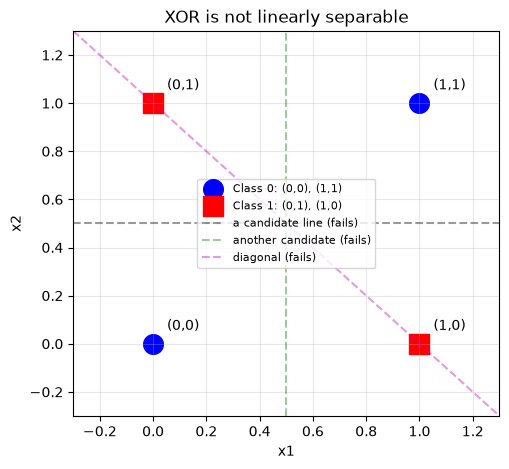

In [15]:
# Q3(b) - XOR on x1-x2 axes
fig, ax = plt.subplots(figsize=(5.5, 5))
ax.scatter([0, 1], [0, 1], c="blue", marker="o", s=200, label="Class 0: (0,0), (1,1)")
ax.scatter([0, 1], [1, 0], c="red", marker="s", s=200, label="Class 1: (0,1), (1,0)")
for (px, py), lab in zip([(0,0),(1,1),(0,1),(1,0)], [0,0,1,1]):
    ax.annotate(f"({px},{py})", (px, py), textcoords="offset points", xytext=(10, 10))
ax.plot([-0.3, 1.3], [0.5, 0.5], "k--", alpha=0.4, label="a candidate line (fails)")
ax.plot([0.5, 0.5], [-0.3, 1.3], "g--", alpha=0.4, label="another candidate (fails)")
ax.plot([-0.3, 1.3], [1.3, -0.3], "m--", alpha=0.4, label="diagonal (fails)")
ax.set_xlim(-0.3, 1.3); ax.set_ylim(-0.3, 1.3)
ax.set_title("XOR is not linearly separable")
ax.set_xlabel("x1"); ax.set_ylabel("x2"); ax.legend(fontsize=8, loc="center"); ax.grid(alpha=0.3)
plt.show()


**Q4 [1.5 marks] — Iris extension.** Add sepal length (feature 0) so you use features (0, 2, 3). Retrain the Part 5 model; report accuracy and macro-F1. Does the extra feature help? Support your answer with numbers.

In [16]:
# Q4
def run_setosa(features):
    X = iris.data[:, features]
    y = (iris.target == 0).astype(int)
    Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.3, random_state=42, stratify=y)
    m = Perceptron(random_state=42).fit(Xtr, ytr)
    pred = m.predict(Xte)
    return m, accuracy_score(yte, pred), f1_score(yte, pred, average="macro"), confusion_matrix(yte, pred)

m2, acc2, f12, cm2 = run_setosa((2, 3))
m3, acc3, f13, cm3 = run_setosa((0, 2, 3))

print(f"{'Features':<22} | {'Accuracy':>8} | {'Macro-F1':>8} | n_iter_")
print("-" * 55)
print(f"{'(2, 3) petal only':<22} | {acc2:>8.4f} | {f12:>8.4f} | {m2.n_iter_}")
print(f"{'(0, 2, 3) + sepal len':<22} | {acc3:>8.4f} | {f13:>8.4f} | {m3.n_iter_}")
print("\nConfusion matrix (0, 2, 3):\n", cm3)
print("coef_ (0, 2, 3):", np.round(m3.coef_[0], 3), "| intercept_:", np.round(m3.intercept_, 3))


Features               | Accuracy | Macro-F1 | n_iter_
-------------------------------------------------------
(2, 3) petal only      |   1.0000 |   1.0000 | 7
(0, 2, 3) + sepal len  |   1.0000 |   1.0000 | 7

Confusion matrix (0, 2, 3):
 [[30  0]
 [ 0 15]]
coef_ (0, 2, 3): [ 4.5 -8.7 -4.1] | intercept_: [2.]


**Result:** The inclusion of the feature of sepal length does not yield any benefit since the model was already working perfectly with accuracy and macro F1 score both at **1.0000**, and the confusion matrix is [[30, 0], [0, 15]], meaning that there were no errors at all.

The Setosa can be linearly separated from the rest by just using the length and width of the petals, meaning that the perceptron is able to achieve 100% accuracy on the test dataset, and hence there will be no error left for the new feature to reduce. The difference is that there is an extra weight added (coef_ = [4.5, -8.7, -4.1], intercept 2.0), which is just another unnecessary parameter with no tangible gain.

**Q5 [1.5 marks] — Synthetic data.** `make_classification(n_samples=200, n_features=2, n_redundant=0, n_clusters_per_class=1, random_state=42)`, 70/30 split. Train your hand-built perceptron and sklearn's. Compare accuracy, epochs, final w and b; plot both boundaries side by side.

              | Test acc | Epochs | w                          | b
------------------------------------------------------------------------
Hand-built    |   0.8167 |    100 | [ 0.307 -0.256]            | 0.200
sklearn       |   0.6667 |      6 | [2.281 0.58 ]              | 2.000

Hand-built final-epoch mistakes: 33 | min mistakes in any epoch: 29
Train accuracy -> hand-built: 0.8 | sklearn: 0.6929


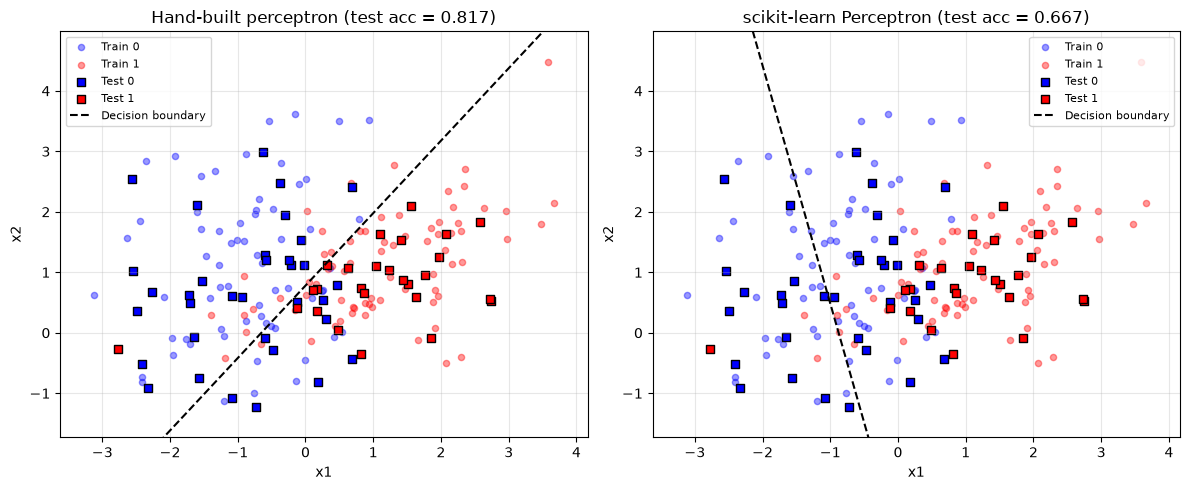

In [17]:
# Q5
Xs, ys = make_classification(n_samples=200, n_features=2, n_redundant=0,
                             n_clusters_per_class=1, random_state=42)
Xs_train, Xs_test, ys_train, ys_test = train_test_split(Xs, ys, test_size=0.3, random_state=42)

# Hand-built perceptron
w_h, b_h, m_h = train_perceptron(Xs_train, ys_train, eta=0.1, max_epochs=100)
pred_h = np.array([predict(w_h, x, b_h) for x in Xs_test])
acc_h = accuracy_score(ys_test, pred_h)

# scikit-learn perceptron
sk = Perceptron(random_state=42).fit(Xs_train, ys_train)
pred_s = sk.predict(Xs_test)
acc_s = accuracy_score(ys_test, pred_s)

print(f"{'':<14}| {'Test acc':>8} | {'Epochs':>6} | {'w':<26} | b")
print("-" * 72)
print(f"{'Hand-built':<14}| {acc_h:>8.4f} | {len(m_h):>6} | {str(np.round(w_h, 3)):<26} | {b_h:.3f}")
print(f"{'sklearn':<14}| {acc_s:>8.4f} | {sk.n_iter_:>6} | {str(np.round(sk.coef_[0], 3)):<26} | {sk.intercept_[0]:.3f}")
print("\nHand-built final-epoch mistakes:", m_h[-1], "| min mistakes in any epoch:", min(m_h))
print("Train accuracy -> hand-built:", round(accuracy_score(ys_train, [predict(w_h, x, b_h) for x in Xs_train]), 4),
      "| sklearn:", round(sk.score(Xs_train, ys_train), 4))

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
xr = (Xs[:, 0].min() - 0.5, Xs[:, 0].max() + 0.5)
for ax, title, (w_, b_), acc in [(axes[0], "Hand-built perceptron", (w_h, b_h), acc_h),
                                 (axes[1], "scikit-learn Perceptron", (sk.coef_[0], sk.intercept_[0]), acc_s)]:
    ax.scatter(Xs_train[ys_train == 0, 0], Xs_train[ys_train == 0, 1], c="blue", s=20, alpha=0.4, label="Train 0")
    ax.scatter(Xs_train[ys_train == 1, 0], Xs_train[ys_train == 1, 1], c="red", s=20, alpha=0.4, label="Train 1")
    ax.scatter(Xs_test[ys_test == 0, 0], Xs_test[ys_test == 0, 1], c="blue", marker="s", edgecolor="k", s=40, label="Test 0")
    ax.scatter(Xs_test[ys_test == 1, 0], Xs_test[ys_test == 1, 1], c="red", marker="s", edgecolor="k", s=40, label="Test 1")
    ax.set_xlim(xr); ax.set_ylim(Xs[:, 1].min() - 0.5, Xs[:, 1].max() + 0.5)
    plot_boundary(ax, w_, b_, x_range=xr)
    ax.set_title(f"{title} (test acc = {acc:.3f})")
    ax.set_xlabel("x1"); ax.set_ylabel("x2"); ax.legend(fontsize=8); ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()


**Comparison (70/30 split, random_state=42):**

| Model | Test accuracy | Epochs | Final w | Final b |
|---|---|---|---|---|
| Hand-built (η = 0.1) | 0.817 | 100 (hit the limit) | [0.307, −0.256] | 0.200 |
| scikit-learn Perceptron | 0.667 | 6 | [2.281, 0.580] | 2.000 |

**Analysis.**These two classes are overlapping, which means that the data is **not linearly separable** and we can't use the perceptron convergence theorem. In my version of perceptron, there was never an epoch without mistakes (the last epoch had 33 mistakes, while the best epoch - 29), so the perceptron ran for 100 epochs. Scikit-learn ran only 6 epochs, since the loss criterion did not get any better according to its tolerance-based termination criterion. Since the weights are changing randomly due to the data being inseparable, the end boundary will be strongly dependent on the place where it stopped and the order of data processing (scikit-learn shuffles data in each epoch, I don't), so the weights of two models differ although the algorithm itself is the same. In this case, it so happens that the hand-made model ends up on a better line (test accuracy 0.817 compared to 0.667): the plot demonstrates that the decision boundary of the hand-made model divides the two clusters at an angle, whereas the decision boundary of scikit-learn's model is a nearly vertical line. As η only scales the weights with the initial value of zero, the discrepancy stems from the process of shuffling and stopping, not η itself. For classes that overlap, such as in this example, a smoother loss (logistic regression) should be used instead of perceptron.